# Kiểm tra 3 seed: V1–V4 và ablation

Seed 42 chạy trên máy nhóm (RTX 4060, torch 2.0.1). Seed 1 và 2 train trên Modal (RTX PRO 6000, torch 2.7.1), rồi dịch và chấm bằng torch 2.0.1 trên T4, đúng môi trường của seed 42. Code: `scripts/modal_3seed.py`, `scripts/tong_hop_3seed.py`.

## 1. Quy tắc ghi trước khi train seed mới

In [1]:
from pathlib import Path
import json, shutil, statistics as st
import pandas as pd
import matplotlib.pyplot as plt
T = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
R = T / "reports/ba_seed"
print((R / "QUY_TAC_3SEED.md").read_text(encoding="utf-8"))

# Quy tắc xử lý 3 seed (ghi TRƯỚC khi train seed mới) – 04/11/2026

Seed: 42 (đã có, chạy trên RTX 4060), 1 và 2 (mới, chạy trên Modal). Phạm vi: V1, V2, V3, V4. Ablation A_r8, A_r32, A_aug giữ 1 seed và ghi rõ.
Cấu hình mỗi bản giữ nguyên như seed 42: 5 epoch, batch 4 × 4, chọn epoch theo BLEU dev cascade. Chỉ đổi seed huấn luyện; dữ liệu train giữ nguyên.
V4 dùng dữ liệu của V3 như seed 42, không xét lại nhánh chọn gốc V2/V3.

1. Báo cáo trung bình ± độ lệch chuẩn (mẫu, n = 3) của dev cascade, dev sạch, test cascade, test sạch, Whisper → dịch. PhoMT test không chạy lại, giữ 1 seed.
2. Bản cuối và demo vẫn là V2 seed 42 (quyết định đã chốt, không đổi theo kết quả 3 seed).
3. Áp lại quy tắc DEV trên trung bình 3 seed như phân tích độ nhạy. Nếu ra bản khác V2 thì ghi rõ trong tài liệu, không đổi bản cuối.
4. Không bỏ seed nào, không chọn seed đẹp. Seed lỗi kỹ thuật thì chạy lại đúng seed đó và ghi lại.
5. Khác phần cứng: thêm 1 job V2 seed 42 trên Modal để đo chênh lệch do máy; job này 

## 2. Kiểm tra phép chấm và đối chứng môi trường

Cùng adapter V2 seed 42 trên tập dev: T4 + torch 2.0.1 cho BLEU 26,45, khớp máy nhóm; RTX PRO 6000 + torch 2.7.1 cho 26,24. Vì vậy mọi số dưới đây đều chấm bằng torch 2.0.1.

Bảng dưới so V2 seed 42 train trên máy nhóm với V2 seed 42 train lại trên Modal. Job đối chứng này không tính vào trung bình. Chênh lệch ở đây cho biết riêng môi trường train đã làm số đổi bao nhiêu.

In [2]:
kq = json.loads((R / "ket_qua_3seed.json").read_text(encoding="utf-8"))
dc = pd.DataFrame(kq["doi_chung_phan_cung_V2_s42"]).T
dc["chênh"] = (dc.iloc[:, 1] - dc.iloc[:, 0]).round(2)
dc

,seed 42 máy nhóm (torch 2.0.1),seed 42 Modal (train torch 2.7.1),chênh
dev cascade,26.45,25.66,-0.79
dev sạch,36.93,36.87,-0.06
test cascade,27.47,27.32,-0.15
test sạch,38.09,37.91,-0.18
Whisper → dịch,19.68,19.66,-0.02


## 3. V1–V4 theo từng seed

`n` là số seed có dữ liệu. V1 seed 42 chưa chạy Whisper → dịch nên mục đó chỉ có 2 seed.

In [3]:
B = pd.read_csv(R / "bang_3seed.csv")
B

,bản,chỉ số,seed 42,seed 1,seed 2,trung bình,độ lệch chuẩn,chrF++ trung bình,n
0,V1,dev cascade,26.47,26.86,26.08,26.47,0.39,52.43,3
1,V1,dev sạch,35.97,36.10,36.27,36.11,0.15,60.12,3
2,V1,test cascade,27.49,28.22,27.77,27.83,0.37,52.57,3
3,V1,test sạch,36.21,36.75,37.42,36.79,0.61,60.10,3
4,V1,Whisper → dịch,NaN,20.50,20.47,20.48,0.02,45.12,2
5,V2,dev cascade,26.45,26.33,27.13,26.64,0.43,52.58,3
6,V2,dev sạch,36.93,36.64,36.67,36.75,0.16,60.95,3
7,V2,test cascade,27.47,27.24,27.30,27.34,0.12,52.76,3
8,V2,test sạch,38.09,37.60,37.71,37.80,0.26,61.14,3
9,V2,Whisper → dịch,19.68,19.40,19.13,19.40,0.28,44.74,3


In [4]:
dat = B.pivot(index="bản", columns="chỉ số", values="trung bình")[["dev cascade", "dev sạch", "test cascade", "test sạch", "Whisper → dịch"]]
sd = B.pivot(index="bản", columns="chỉ số", values="độ lệch chuẩn")[dat.columns]
(dat.round(2).astype(str) + " ± " + sd.round(2).astype(str))

chỉ số,dev cascade,dev sạch,test cascade,test sạch,Whisper → dịch
bản,,,,,
V1,26.47 ± 0.39,36.11 ± 0.15,27.83 ± 0.37,36.79 ± 0.61,20.48 ± 0.02
V2,26.64 ± 0.43,36.75 ± 0.16,27.34 ± 0.12,37.8 ± 0.26,19.4 ± 0.28
V3,25.67 ± 0.95,36.15 ± 0.32,27.39 ± 0.36,37.02 ± 0.31,19.56 ± 0.27
V4,25.81 ± 0.67,36.32 ± 0.81,26.71 ± 0.58,37.46 ± 1.03,19.72 ± 0.78


## 4. Áp lại quy tắc DEV trên trung bình 3 seed

In [5]:
print("Đỉnh dev cascade trung bình:", kq["M_dev_cascade_tb"])
print("Nhóm hoà (cách đỉnh ≤ 0,5):", kq["nhom_hoa"])
print("Quy tắc trên trung bình ra:", kq["quy_tac_tren_trung_binh_ra"], "· bản cuối giữ:", kq["ban_cuoi_giu_nguyen"])
print("Epoch tốt nhất:", kq["epoch_tot_nhat"])

Đỉnh dev cascade trung bình: 26.64
Nhóm hoà (cách đỉnh ≤ 0,5): ['V1', 'V2']
Quy tắc trên trung bình ra: V2 · bản cuối giữ: V2
Epoch tốt nhất: {'V1_s1': 1, 'V1_s2': 1, 'V2_s1': 1, 'V2_s2': 1, 'V3_s1': 1, 'V3_s2': 1, 'V4_s1': 1, 'V4_s2': 4}


## 5. So với B0, tính riêng từng seed

In [6]:
J = lambda p: json.loads(Path(p).read_text(encoding="utf-8"))
b0c, b0s = J(T / "runs/mt/B0/fleurs_test_asr_pho/score.json")["BLEU"], J(T / "runs/mt/B0/fleurs_test_clean/score.json")["BLEU"]
v2 = B[B["bản"] == "V2"].set_index("chỉ số")
d = {s: round(v2.loc["test cascade", s] - b0c, 2) for s in ("seed 42", "seed 1", "seed 2")}
print("Δ test cascade V2 so với B0:", d, "· trung bình", round(st.mean(d.values()), 2), "· độ lệch chuẩn", round(st.stdev(d.values()), 2))
c = {s: round(v2.loc["test sạch", s] - b0s, 2) for s in ("seed 42", "seed 1", "seed 2")}
print("Δ test sạch V2 so với B0 (ngưỡng ≥ 38,27):", c, "· trung bình", round(st.mean(c.values()), 2))
print("Số seed đạt ngưỡng dịch sạch:", sum(x >= 0 for x in c.values()), "/ 3")

Δ test cascade V2 so với B0: {'seed 42': 4.78, 'seed 1': 4.55, 'seed 2': 4.61} · trung bình 4.65 · độ lệch chuẩn 0.12
Δ test sạch V2 so với B0 (ngưỡng ≥ 38,27): {'seed 42': -0.18, 'seed 1': -0.67, 'seed 2': -0.56} · trung bình -0.47
Số seed đạt ngưỡng dịch sạch: 0 / 3


## 6. Ablation một yếu tố, 3 seed

Cột cuối so với V2 theo từng cặp cùng seed. Mục Whisper → dịch của ablation chỉ có 2 seed.

In [7]:
A = pd.read_csv(R / "bang_ablation_3seed.csv").fillna("")
A

,bản,chỉ số,seed 42,seed 1,seed 2,trung bình,độ lệch chuẩn,n,"Δ so với V2 (cùng seed, trung bình)"
0,V2,dev cascade,26.45,26.33,27.13,26.64,0.43,3,
1,V2,dev sạch,36.93,36.64,36.67,36.75,0.16,3,
2,V2,test cascade,27.47,27.24,27.30,27.34,0.12,3,
3,V2,test sạch,38.09,37.60,37.71,37.80,0.26,3,
4,V2,Whisper → dịch,19.68,19.40,19.13,19.40,0.28,3,
5,A_r8,dev cascade,25.97,26.76,26.99,26.57,0.54,3,"-0.06 (-0.48, +0.43, -0.14)"
6,A_r8,dev sạch,36.74,35.95,37.42,36.70,0.74,3,"-0.04 (-0.19, -0.69, +0.75)"
7,A_r8,test cascade,27.26,27.30,27.23,27.26,0.04,3,"-0.07 (-0.21, +0.06, -0.07)"
8,A_r8,test sạch,37.96,37.98,37.76,37.90,0.12,3,"+0.10 (-0.13, +0.38, +0.05)"
9,A_r8,Whisper → dịch,,19.36,19.15,19.25,0.15,2,"-0.01 (-0.04, +0.02)"


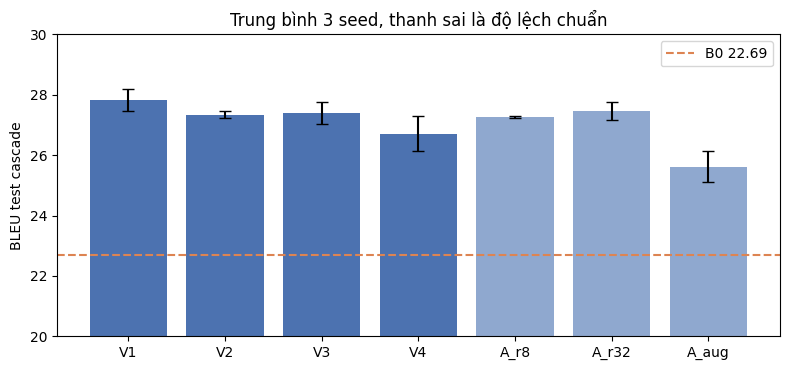

In [8]:
x = B[B["chỉ số"] == "test cascade"]; y = A[(A["chỉ số"] == "test cascade") & (A["bản"] != "V2")]
ten = list(x["bản"]) + list(y["bản"]); tb = list(x["trung bình"]) + list(y["trung bình"]); sd_ = list(x["độ lệch chuẩn"]) + list(y["độ lệch chuẩn"])
fig, ax = plt.subplots(figsize=(8, 3.8)); ax.bar(ten, tb, yerr=sd_, capsize=4, color=["#4c72b0"] * 4 + ["#8fa8cf"] * 3)
ax.axhline(b0c, color="#dd8452", ls="--", label=f"B0 {b0c}"); ax.set_ylabel("BLEU test cascade"); ax.set_ylim(20, 30); ax.legend(); ax.set_title("Trung bình 3 seed, thanh sai là độ lệch chuẩn"); plt.tight_layout(); fig.savefig(R / "bieu_do_3seed.png", dpi=150); plt.show()

## 7. Ghi thêm vào workbook

In [9]:
from openpyxl import load_workbook
X = T / "reports/danh_gia/bang_ket_qua.xlsx"
with pd.ExcelWriter(X, engine="openpyxl", mode="a", if_sheet_exists="replace") as w:
    B.to_excel(w, sheet_name="3 seed V1-V4", index=False); A.to_excel(w, sheet_name="3 seed ablation", index=False)
print(load_workbook(X).sheetnames)

['Baseline Comparison', 'Proposed & Ablation', 'Error & Feasibility', 'So sanh chung (test)', '3 seed V1-V4', '3 seed ablation']
